In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
print("Seaborn_version",sns.__version__)

Seaborn_version 0.13.2


In [4]:
df=pd.read_csv("C:\\Users\\ABC\\Downloads\\student_tech_profile.csv")
df.head()

,student_id,branch,year,gender,coding_hours_per_week,problems_solved,github_commits,projects_completed,sleep_hours,attendance_pct,cgpa,internship_done,placed,package_lpa
0,S1000,MECH,2,Male,6.4,101,0,3,5.1,100.0,7.29,No,Yes,14.08
1,S1001,EEE,3,Male,2.7,53,15,0,8.0,78.4,7.04,No,Yes,9.34
2,S1002,IT,3,Male,17.5,195,0,6,6.8,65.7,8.01,Yes,Yes,11.11
3,S1003,EEE,3,Male,9.7,180,57,0,5.5,92.5,7.41,No,Yes,3.56
4,S1004,CSE,1,Male,14.5,166,52,2,5.7,63.6,6.70,No,No,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             600 non-null    str    
 1   branch                 600 non-null    str    
 2   year                   600 non-null    int64  
 3   gender                 600 non-null    str    
 4   coding_hours_per_week  600 non-null    float64
 5   problems_solved        600 non-null    int64  
 6   github_commits         600 non-null    int64  
 7   projects_completed     600 non-null    int64  
 8   sleep_hours            600 non-null    float64
 9   attendance_pct         600 non-null    float64
 10  cgpa                   600 non-null    float64
 11  internship_done        600 non-null    str    
 12  placed                 600 non-null    str    
 13  package_lpa            289 non-null    float64
dtypes: float64(5), int64(4), str(5)
memory usage: 65.8 KB


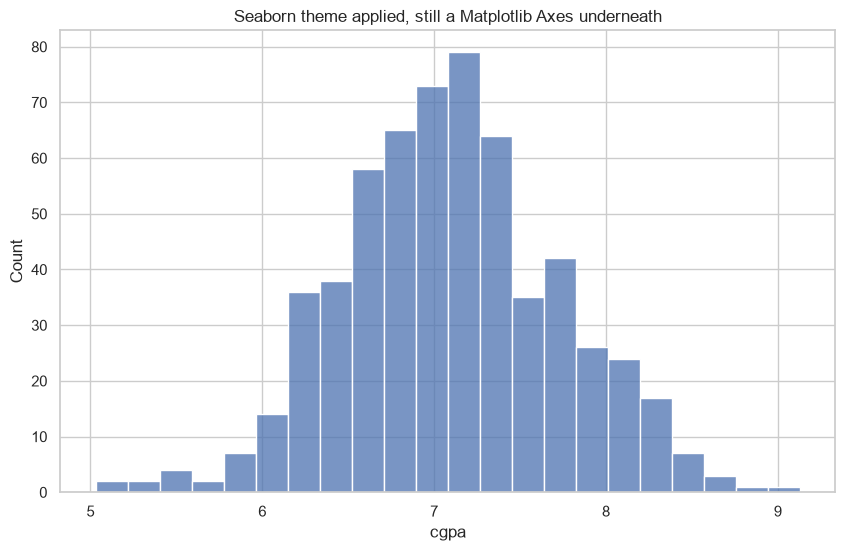

In [8]:
sns.set_theme(style="whitegrid", palette="deep")
sns.set_context("notebook")
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=df, x="cgpa", ax=ax)
ax.set_title("Seaborn theme applied, still a Matplotlib Axes underneath")
plt.show()

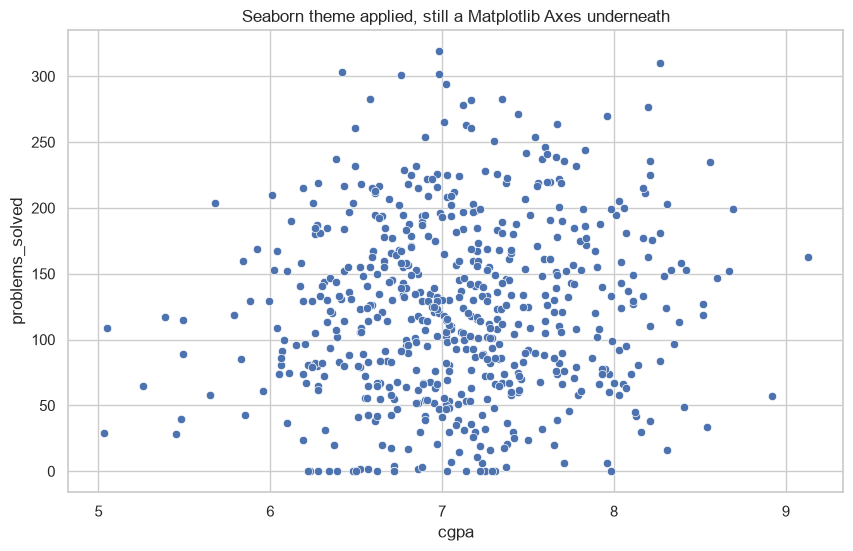

In [13]:
sns.set_theme(style="whitegrid", palette="deep")
sns.set_context("notebook")
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="cgpa",y="problems_solved" ,ax=ax)
ax.set_title("Seaborn theme applied, still a Matplotlib Axes underneath")
plt.show()

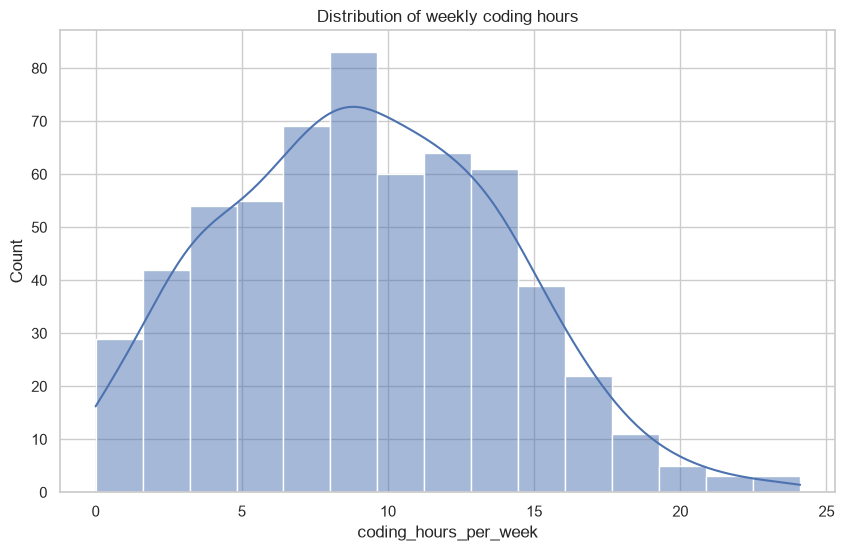

In [14]:
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df,x="coding_hours_per_week",kde=True,ax=ax)
ax.set_title("Distribution of weekly coding hours")
plt.show()


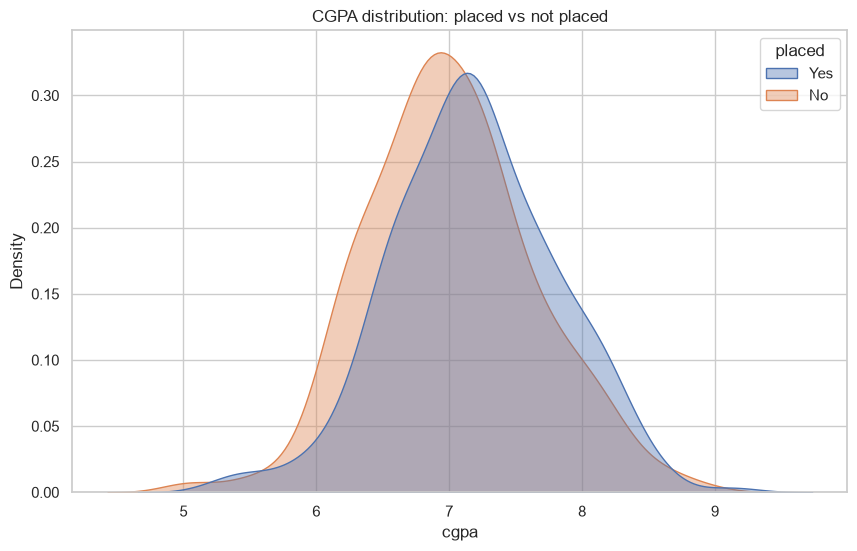

            mean  median
placed                  
No      7.009260    6.97
Yes     7.182907    7.17


In [15]:
fig,ax=plt.subplots(figsize=(10,6))
sns.kdeplot(data=df,x="cgpa",hue="placed",fill=True,alpha=0.4,ax=ax)
ax.set_title("CGPA distribution: placed vs not placed")
plt.show()
print(df.groupby("placed")["cgpa"].agg(["mean","median"]))

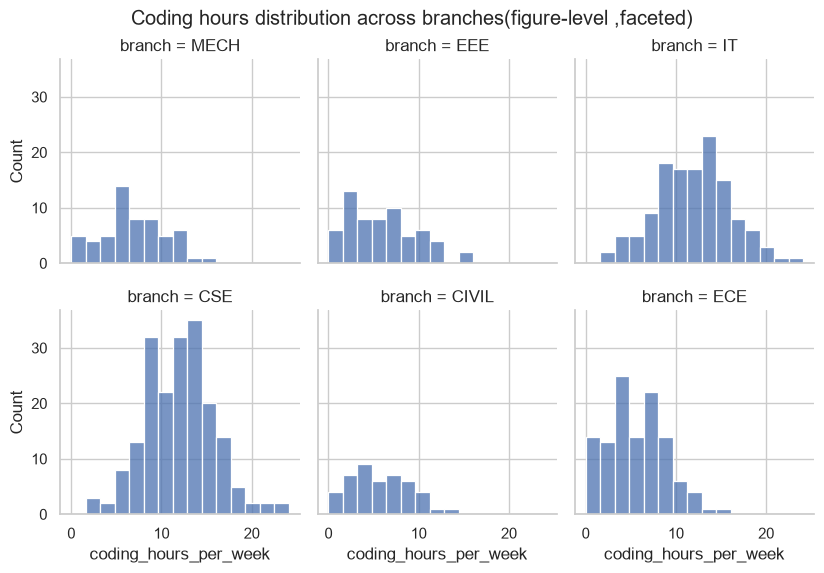

In [43]:
sns.displot(data=df,x="coding_hours_per_week",col="branch",col_wrap=3,height=2.8)
plt.suptitle("Coding hours distribution across branches(figure-level ,faceted)",y=1.02)
plt.show()

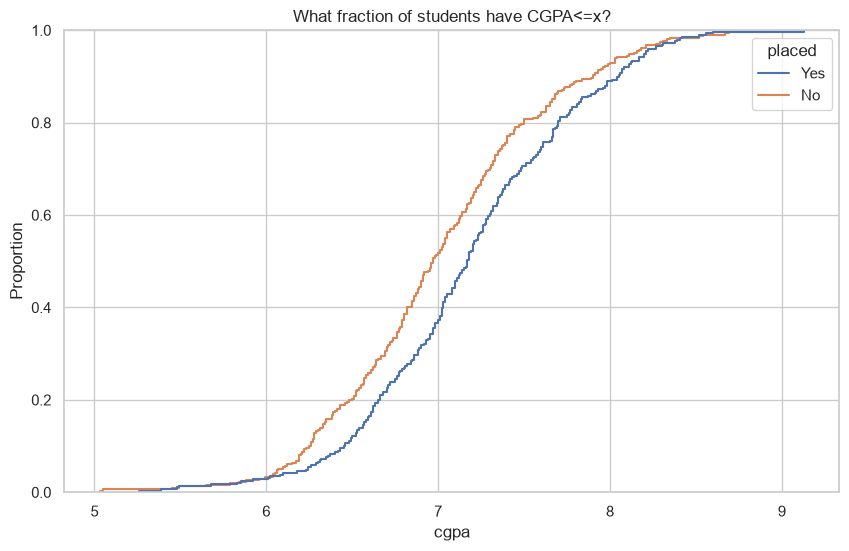

In [17]:
fig,ax=plt.subplots(figsize=(10,6))
sns.ecdfplot(data=df,x="cgpa",hue="placed",ax=ax)
ax.set_title("What fraction of students have CGPA<=x?")
plt.show()

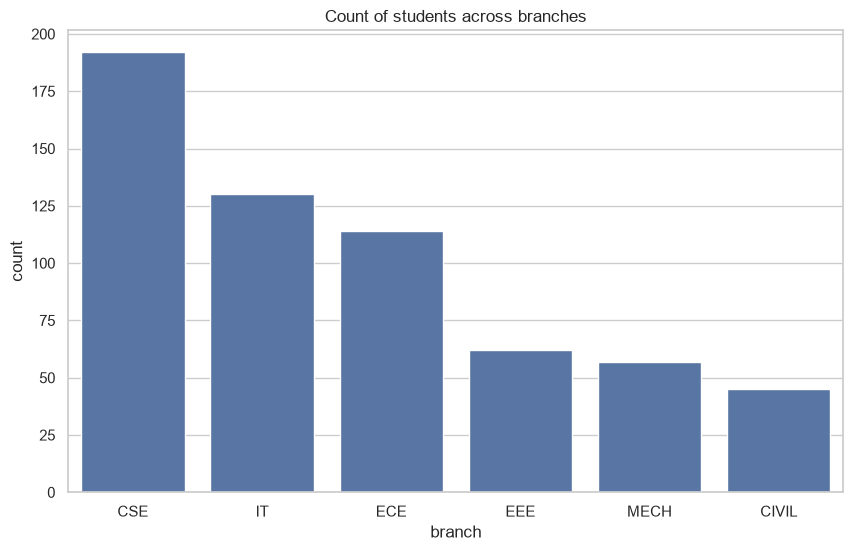

In [22]:
fig,ax=plt.subplots(figsize=(10,6))
sns.countplot(data=df,x="branch",order=df["branch"].value_counts().index,ax=ax)
ax.set_title("Count of students across branches")
plt.show()

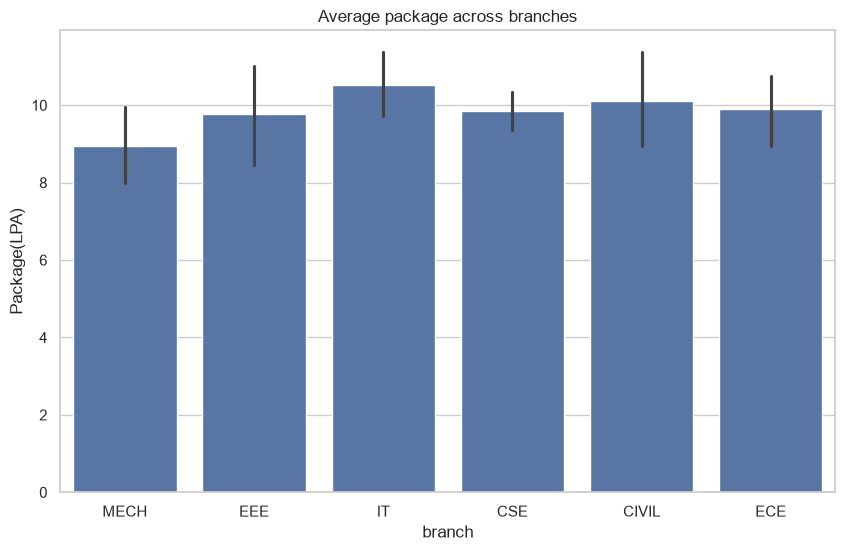

In [27]:
fig,ax=plt.subplots(figsize=(10,6))
sns.barplot(data=df,x="branch",y="package_lpa",ax=ax,errorbar="ci")
ax.set_title("Average package across branches")
ax.set_ylabel("Package(LPA)")
plt.show()

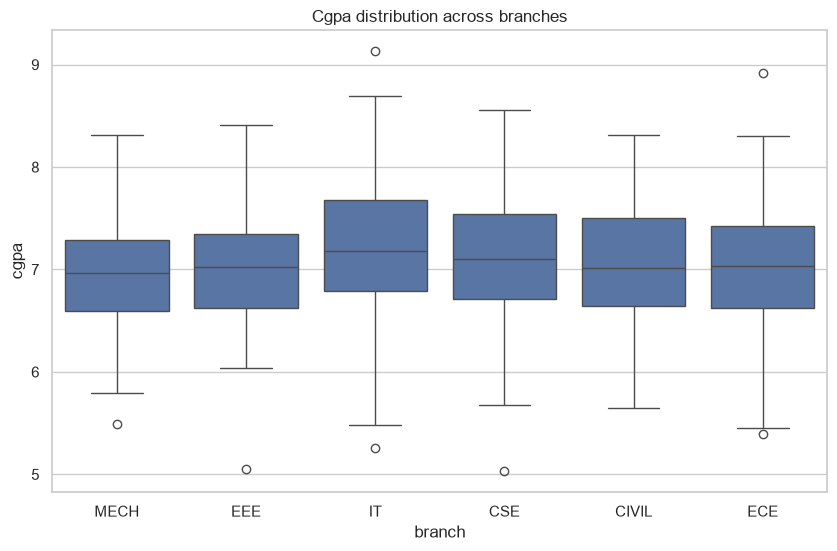

In [28]:
fig,ax=plt.subplots(figsize=(10,6))
sns.boxplot(data=df,x="branch",y="cgpa",ax=ax)
ax.set_title("Cgpa distribution across branches")
plt.show()

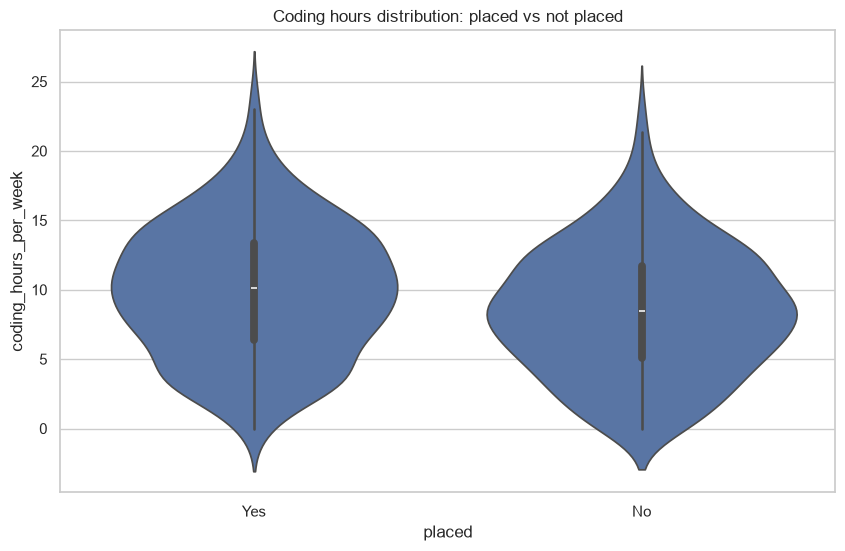

In [29]:
fig,ax=plt.subplots(figsize=(10,6))
sns.violinplot(data=df,x="placed",y="coding_hours_per_week",ax=ax)
ax.set_title("Coding hours distribution: placed vs not placed")
plt.show()

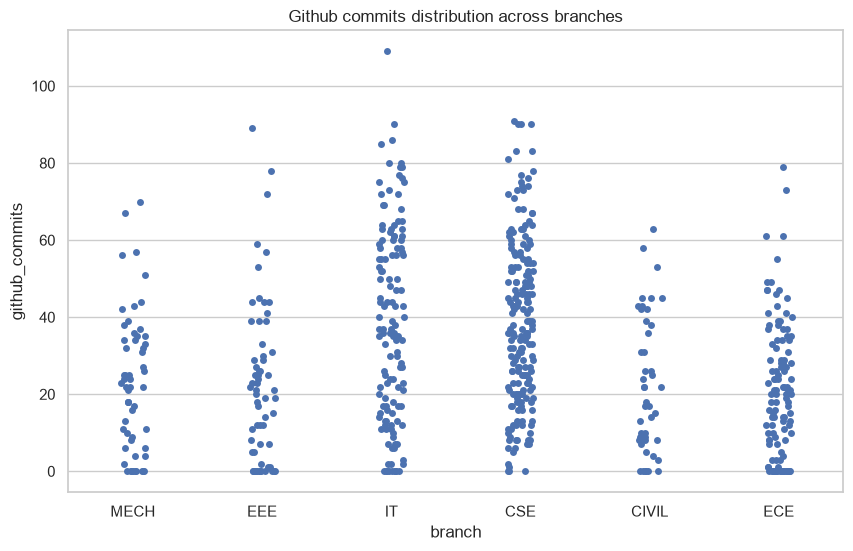

In [34]:
fig,ax=plt.subplots(figsize=(10,6))
sns.stripplot(data=df,x="branch",y="github_commits",ax=ax)
ax.set_title("Github commits distribution across branches")
plt.show()

c:\Users\ABC\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 6.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


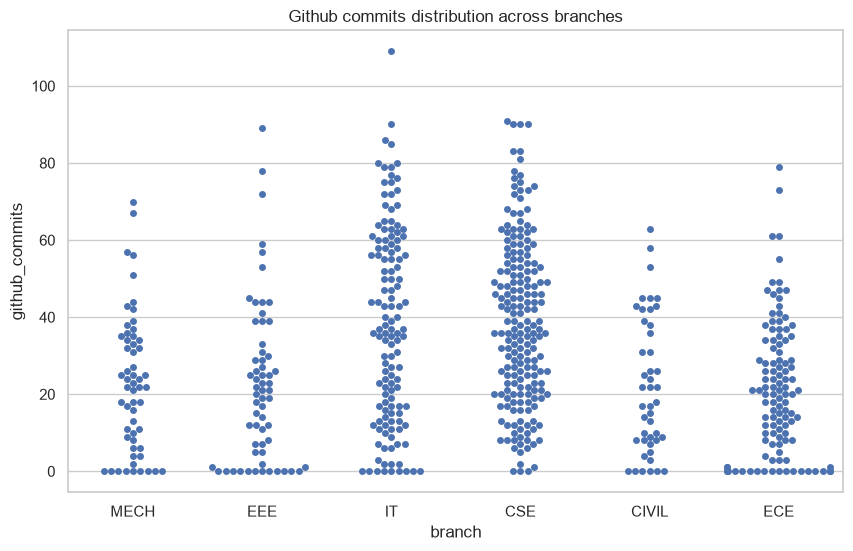

In [36]:
fig,ax=plt.subplots(figsize=(10,6))
sns.swarmplot(data=df,x="branch",y="github_commits",ax=ax)
ax.set_title("Github commits distribution across branches")
plt.show()

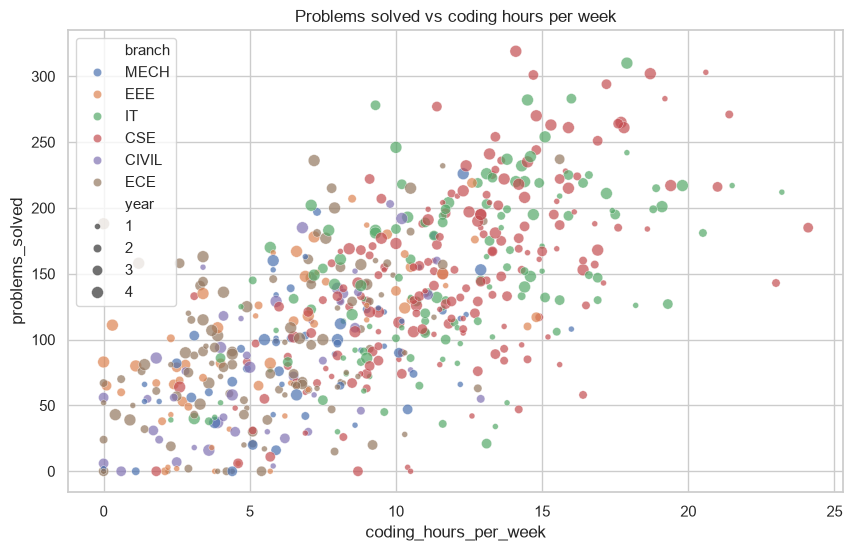

In [37]:
fig,ax=plt.subplots(figsize=(10,6))
sns.scatterplot(data=df,x="coding_hours_per_week",y="problems_solved",hue="branch",size="year",alpha=0.7,ax=ax)
ax.set_title("Problems solved vs coding hours per week")
plt.show()

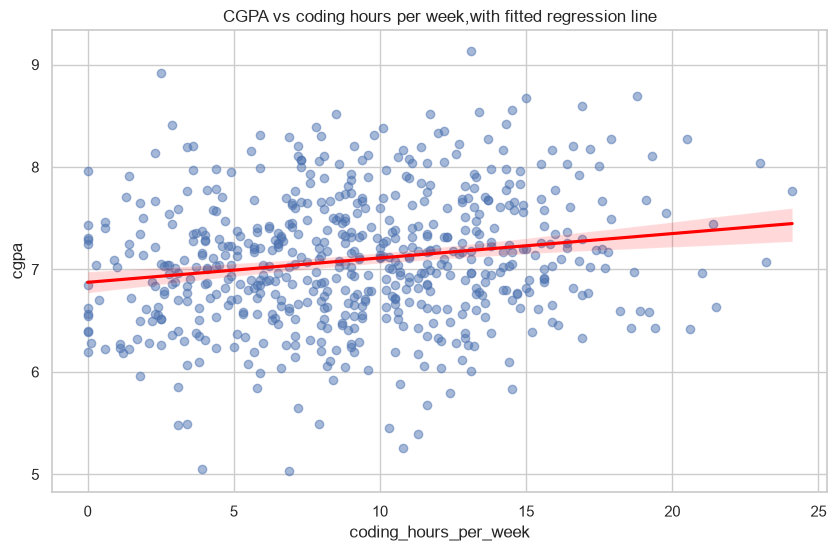

Correlation between coding hours per week and CGPA: 0.18


In [38]:
fig,ax=plt.subplots(figsize=(10,6))
sns.regplot(data=df,x="coding_hours_per_week",y="cgpa",scatter_kws={"alpha":0.5},line_kws={"color":"red"},ax=ax)
ax.set_title("CGPA vs coding hours per week,with fitted regression line")
plt.show()

corr=df["coding_hours_per_week"].corr(df["cgpa"])
print(f"Correlation between coding hours per week and CGPA: {corr:.2f}")

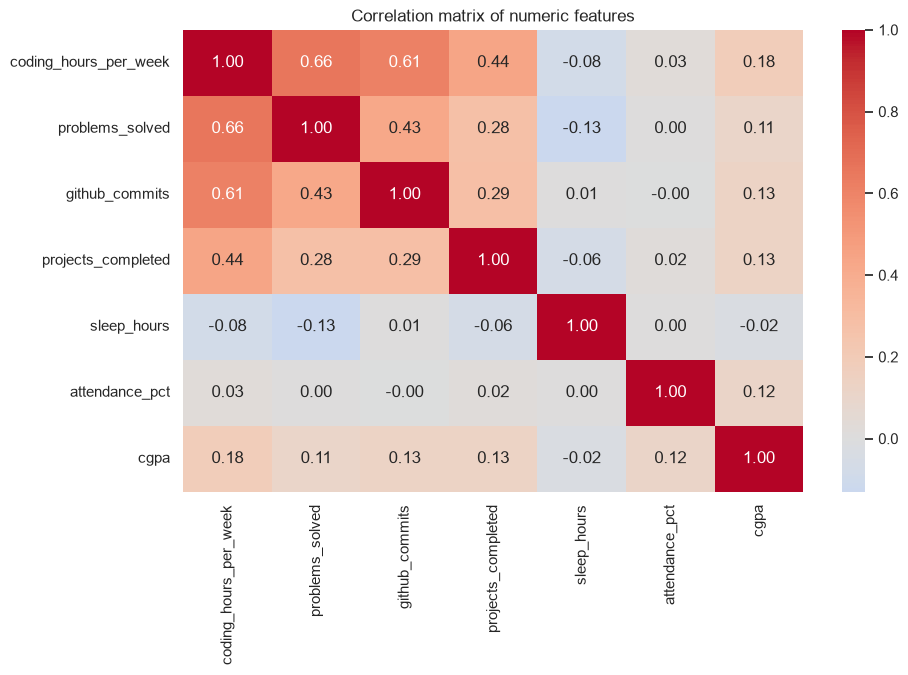

In [40]:
numeric_cols=["coding_hours_per_week","problems_solved","github_commits","projects_completed","sleep_hours","attendance_pct","cgpa"]
corr_matrix=df[numeric_cols].corr()
fig,ax=plt.subplots(figsize=(10,6))
sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0,ax=ax)
ax.set_title("Correlation matrix of numeric features")
plt.show()

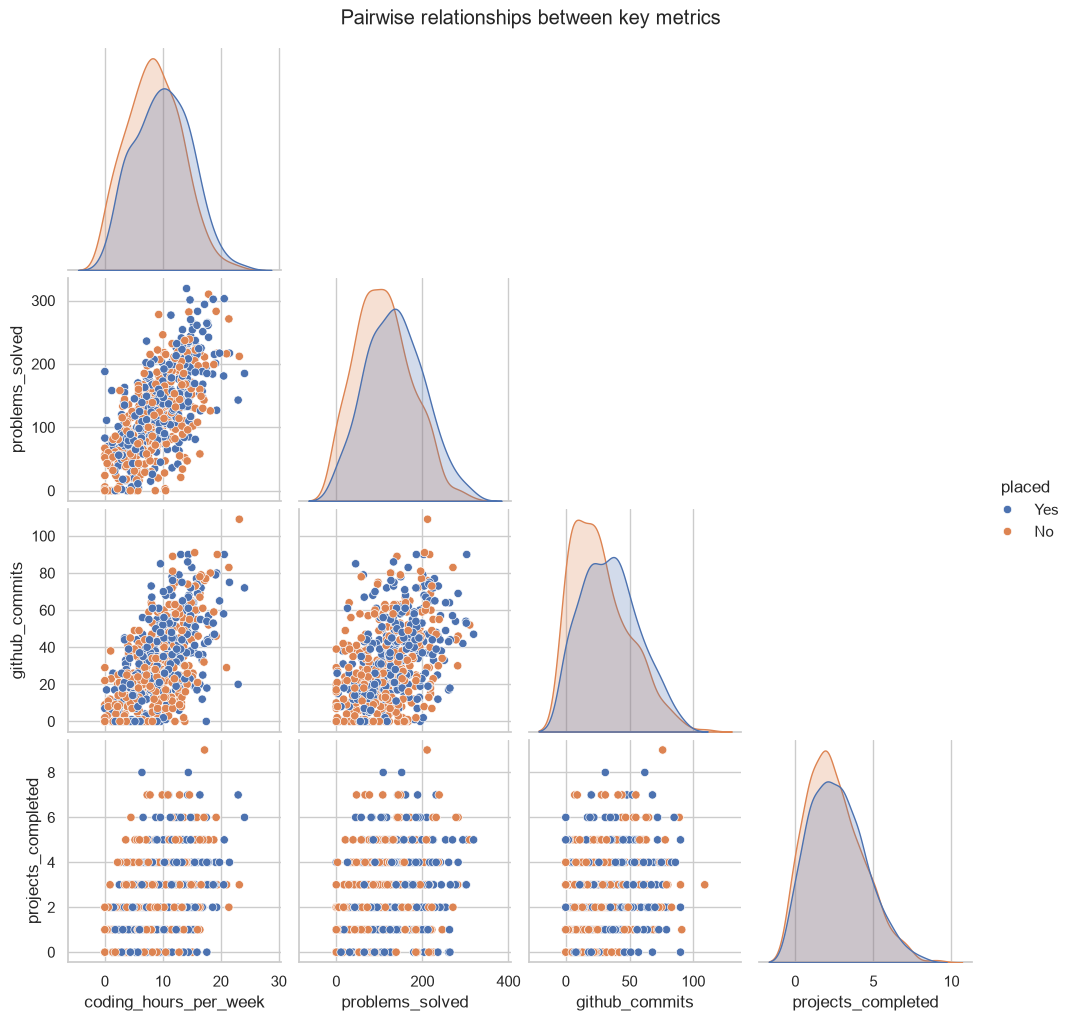

In [41]:
sns.pairplot(df[numeric_cols[:4] + ["placed"]], hue="placed", corner=True)
plt.suptitle("Pairwise relationships between key metrics", y=1.02)
plt.show()


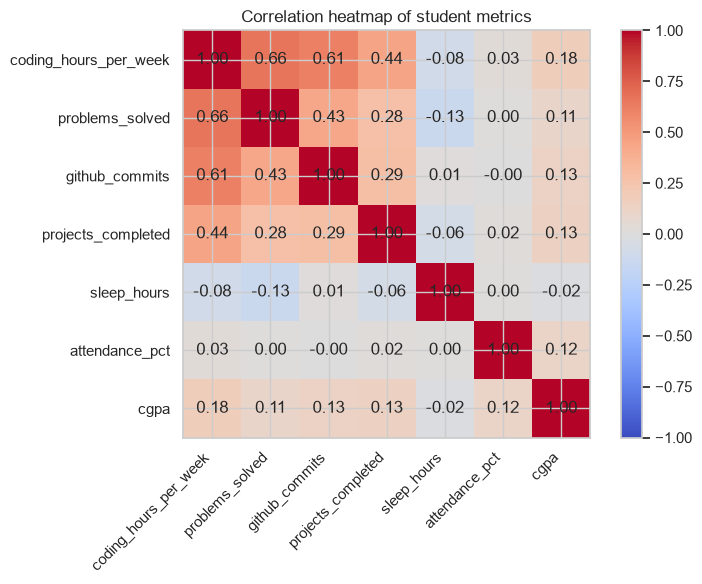

In [64]:
import matplotlib.pyplot as plt

numeric_cols = ["coding_hours_per_week", "problems_solved", "github_commits",
                "projects_completed", "sleep_hours", "attendance_pct", "cgpa"]

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticklabels(numeric_cols)

for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center", va="center")

fig.colorbar(im, ax=ax)
ax.set_title("Correlation heatmap of student metrics")

plt.tight_layout()
plt.show()

Use `student_tech_profile.csv` for all tasks unless stated otherwise.

### Beginner
1. Plot a `histplot` of `sleep_hours` with `kde=True`.
2. Use `countplot` to show how many students are in each `year`.
3. Use `boxplot` to compare `attendance_pct` across `branch`.

### AI/ML & engineering-focused
4. Use `scatterplot` to plot `github_commits` vs `problems_solved`, coloured by `placed`. What pattern do you see?
5. Build a correlation heatmap using only `sleep_hours`, `coding_hours_per_week`, `cgpa`, and `attendance_pct`. Is sleep positively or negatively related to coding hours?
6. Use `lmplot` or `regplot` to check whether `attendance_pct` predicts `cgpa`. Report the correlation coefficient.
7. Use `pairplot` with `hue="internship_done"` on any 3–4 numeric columns of your choice, and write one sentence on the most interesting pattern you notice.

Write your code (and a one-line comment with your observation) in the cells below.

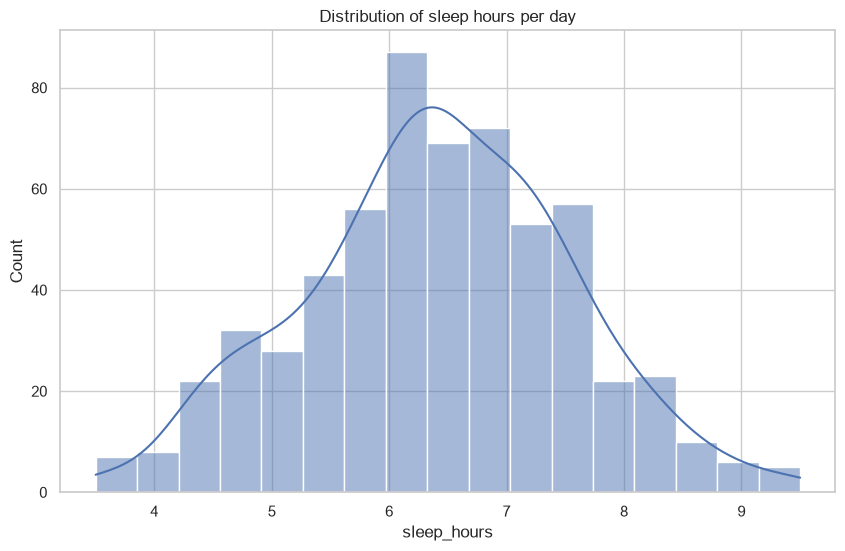

In [50]:
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df,x="sleep_hours",kde=True,ax=ax)
ax.set_title("Distribution of sleep hours per day")
plt.show()

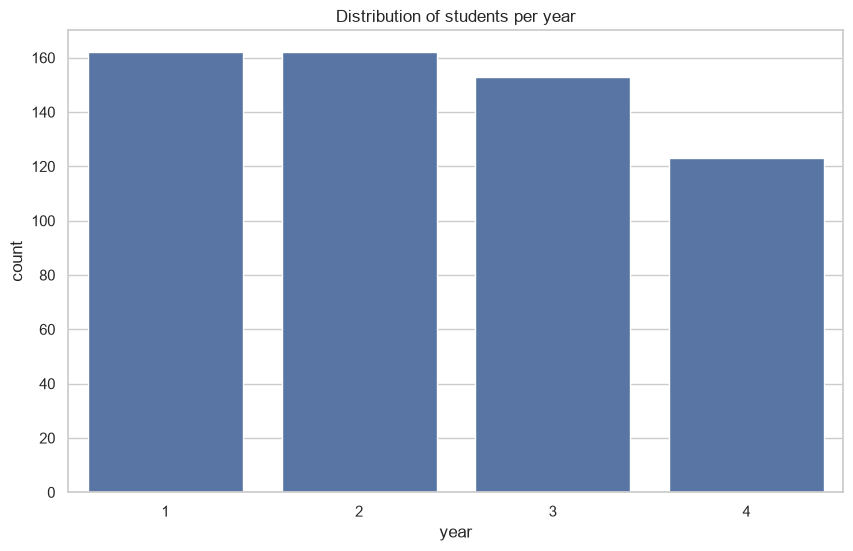

In [52]:
fig,ax=plt.subplots(figsize=(10,6))
sns.countplot(data=df,x="year",ax=ax)
ax.set_title("Distribution of students per year")
plt.show()

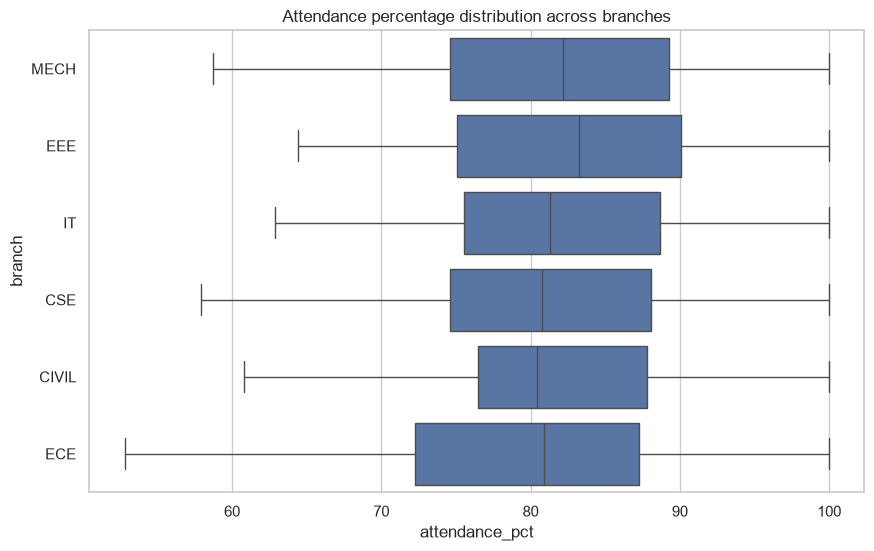

In [56]:
fig,ax=plt.subplots(figsize=(10,6))
sns.boxplot(data=df,x="attendance_pct",y="branch",ax=ax)
ax.set_title("Attendance percentage distribution across branches")
plt.show()

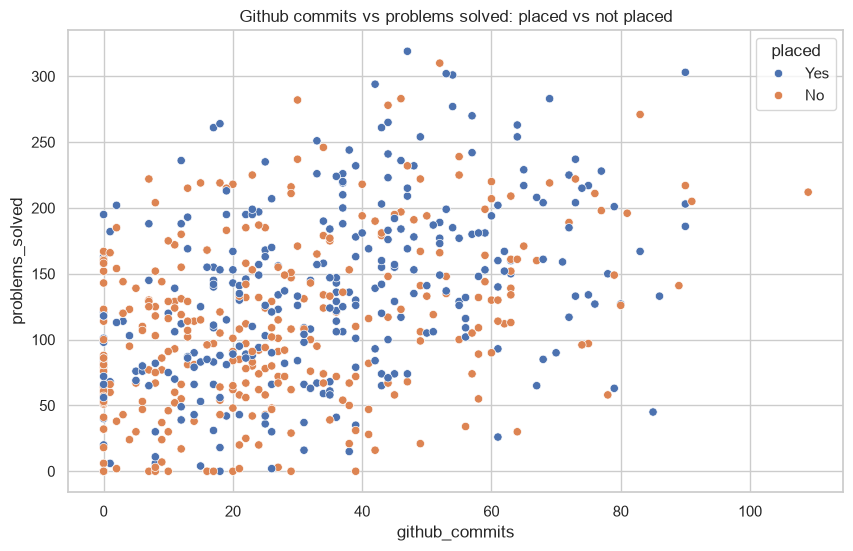

In [60]:
fig,ax=plt.subplots(figsize=(10,6))
sns.scatterplot(data=df,x="github_commits",y="problems_solved",hue="placed",ax=ax)
ax.set_title("Github commits vs problems solved: placed vs not placed")
plt.show()

From this type of plot, look for whether the dots move upward from left to right.

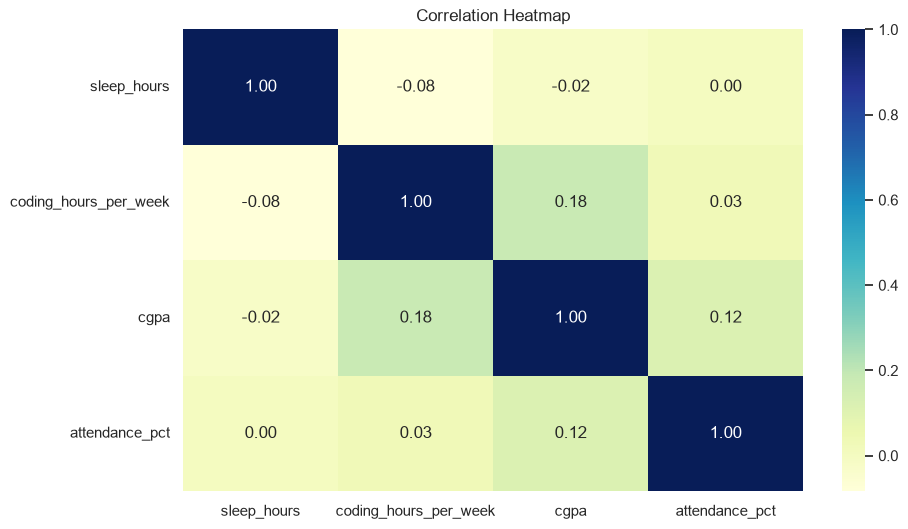

In [62]:
fig,ax=plt.subplots(figsize=(10,6))
corr=df[["sleep_hours","coding_hours_per_week","cgpa","attendance_pct"]].corr()
sns.heatmap(corr,annot=True,fmt=".2f",cmap="YlGnBu",ax=ax)
ax.set_title("Correlation Heatmap")
plt.show()

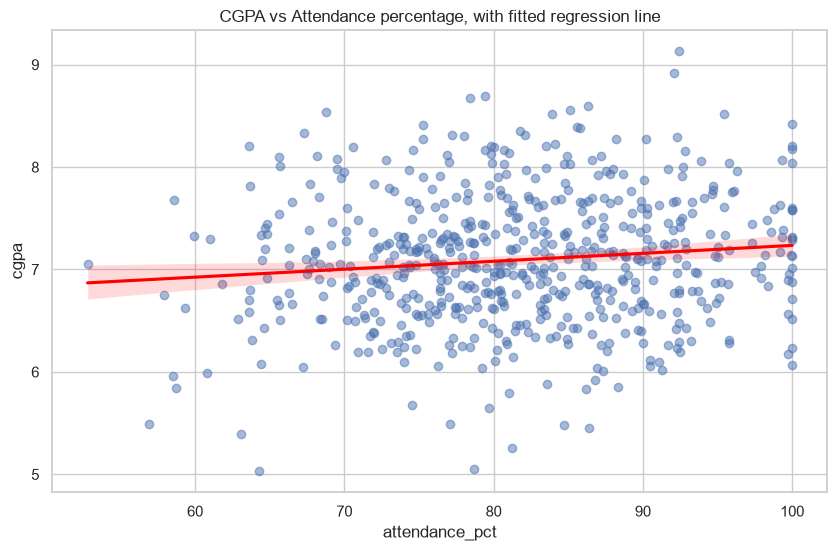

In [65]:
fig,ax=plt.subplots(figsize=(10,6))
sns.regplot(data=df,x="attendance_pct",y="cgpa",scatter_kws={"alpha":0.5},line_kws={"color":"red"},ax=ax)
ax.set_title("CGPA vs Attendance percentage, with fitted regression line")
plt.show()

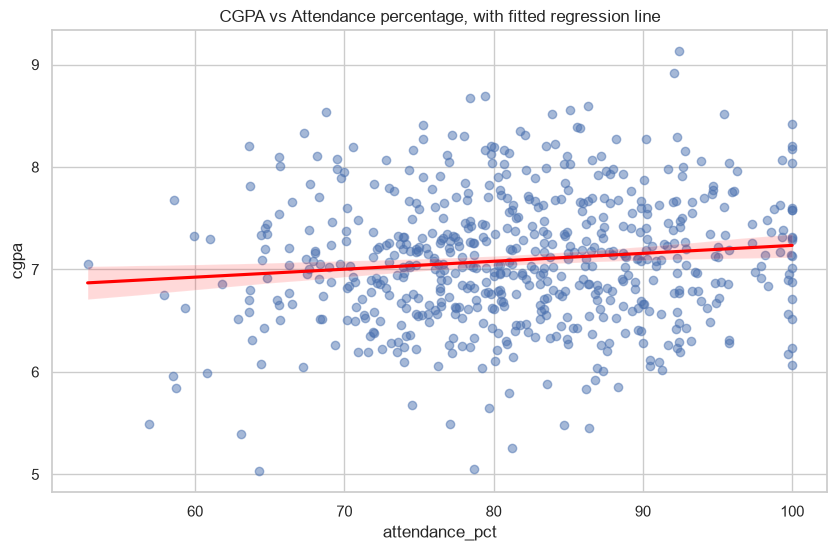

In [70]:
fig,ax=plt.subplots(figsize=(10,6))
sns.regplot(data=df,x="attendance_pct",y="cgpa",
            scatter_kws={"alpha":0.5},
            line_kws={"color":"red"},
            ax=ax)
ax.set_title("CGPA vs Attendance percentage, with fitted regression line")
plt.show()